# DS605 Lab 7 — Image Representation, PCA, Eigenfaces and Face Recognition

**Dataset:** AT&T Database of Faces (ORL)  
**Implementation constraint:** PCA/eigenface calculations use NumPy linear algebra; `sklearn.decomposition.PCA` is not used. Scikit-learn is used only for the final traditional-classifier comparison and train/test splitting.



## 1. Imports and reproducibility

The notebook uses NumPy for all PCA calculations, Matplotlib for figures, Pillow for image reading, and scikit-learn only for splitting and traditional classifiers/metrics.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile, BadZipFile
import urllib.error
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("NumPy:", np.__version__)
print("Dataset directory:", DATA_DIR.resolve())
print("Figures will be saved to:", FIGURE_DIR.resolve())

NumPy: 2.1.3
Dataset directory: /content/data
Figures will be saved to: /content/figures


## 2. Download and locate the ORL dataset

The ORL dataset normally contains 40 subject folders (`s1` through `s40`), each with 10 grayscale face images. The original images are typically 92 × 112 pixels, but the loader checks the actual dimensions rather than assuming them.

In [2]:
ARCHIVE_PATH = DATA_DIR / "att_faces.zip"
EXTRACT_DIR = DATA_DIR / "att_faces"
DATASET_URLS = [
    "https://www.cl.cam.ac.uk/Research/DTG/attarchive/pub/data/att_faces.zip",
    "https://www.cl.cam.ac.uk/Research/DTG/attarchive/pub/data/att_faces.tar.Z",
]

def find_subject_root(base: Path):
    """Find the directory containing subject folders such as s1, s2, ... ."""
    if not base.exists():
        return None
    candidates = [base] + [p for p in base.rglob("*") if p.is_dir()]
    for candidate in candidates:
        subject_dirs = [p for p in candidate.iterdir()
                        if p.is_dir() and p.name.lower().startswith("s")
                        and p.name[1:].isdigit()]
        if len(subject_dirs) >= 2:
            return candidate
    return None

dataset_root = find_subject_root(EXTRACT_DIR) or find_subject_root(DATA_DIR)

if dataset_root is None:
    downloaded = False
    for url in DATASET_URLS:
        try:
            print(f"Trying dataset URL: {url}")
            temp_path = DATA_DIR / Path(url).name
            urlretrieve(url, temp_path)
            if temp_path.suffix.lower() == ".zip":
                with ZipFile(temp_path) as zf:
                    zf.extractall(EXTRACT_DIR)
                downloaded = True
                break
            else:
                print("This archive format may require manual extraction.")
        except (urllib.error.URLError, TimeoutError, OSError, BadZipFile) as exc:
            print("Download attempt failed:", exc)

    dataset_root = find_subject_root(EXTRACT_DIR) or find_subject_root(DATA_DIR)

if dataset_root is None:
    raise FileNotFoundError(
        "Could not locate ORL subject folders. Please download att_faces.zip from the "
        "ORL/AT&T archive, place it in the data/ directory, extract it, and rerun this cell. "
        "The extracted folder should contain subject directories such as s1, s2, ..., s40."
    )

print("Found dataset at:", dataset_root.resolve())

Trying dataset URL: https://www.cl.cam.ac.uk/Research/DTG/attarchive/pub/data/att_faces.zip
Found dataset at: /content/data/att_faces


## 3. Load images, inspect dimensions, flatten images, and create labels

Each image is read in grayscale, converted to a NumPy array, and flattened into a one-dimensional vector. All images must have the same dimensions to form a single image matrix.

In [3]:
image_vectors = []
subject_labels = []
image_paths = []
image_shapes = []

subject_dirs = sorted(
    [p for p in dataset_root.iterdir()
     if p.is_dir() and p.name.lower().startswith("s") and p.name[1:].isdigit()],
    key=lambda p: int(p.name[1:])
)

for subject_dir in subject_dirs:
    subject_id = int(subject_dir.name[1:])
    files = sorted(
        [p for p in subject_dir.iterdir() if p.is_file()],
        key=lambda p: p.name
    )
    for path in files:
        try:
            with Image.open(path) as im:
                gray = im.convert("L")
                arr = np.asarray(gray, dtype=np.uint8)
        except Exception as exc:
            warnings.warn(f"Skipping unreadable file {path}: {exc}")
            continue
        image_shapes.append(arr.shape)
        image_vectors.append(arr.reshape(-1).astype(np.float64))
        subject_labels.append(subject_id)
        image_paths.append(path)

if not image_vectors:
    raise RuntimeError(f"No readable images found under {dataset_root}")

unique_shapes = sorted(set(image_shapes))
if len(unique_shapes) != 1:
    raise ValueError(f"Images have inconsistent dimensions: {unique_shapes}")

image_height, image_width = unique_shapes[0]
X = np.vstack(image_vectors)
y = np.asarray(subject_labels, dtype=int)
image_paths = np.asarray(image_paths, dtype=object)

n_images, n_pixels = X.shape
n_subjects = len(np.unique(y))

print(f"Number of images: {n_images}")
print(f"Number of subjects: {n_subjects}")
print(f"Image dimensions: {image_height} × {image_width}")
print(f"Pixels per image / raw features: {n_pixels}")
print(f"Pixel intensity range: {X.min():.0f} to {X.max():.0f}")
print("Image matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("Images per subject (min/max):",
      min(np.bincount(y)), max(np.bincount(y)))

assert X.ndim == 2 and X.shape[0] == len(y)
assert len(unique_shapes) == 1
assert np.isfinite(X).all()

Number of images: 400
Number of subjects: 40
Image dimensions: 112 × 92
Pixels per image / raw features: 10304
Pixel intensity range: 0 to 251
Image matrix shape: (400, 10304)
Label vector shape: (400,)
Images per subject (min/max): 0 10


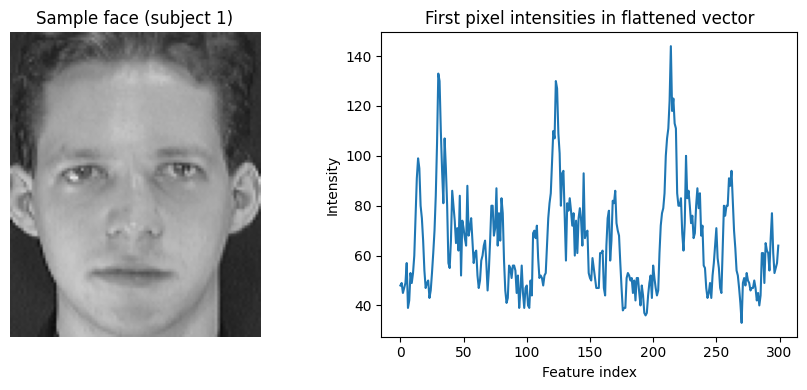

In [4]:
# Inspect a sample image and its flattened feature vector.
sample_idx = 0
sample_image = X[sample_idx].reshape(image_height, image_width)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(sample_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Sample face (subject {y[sample_idx]})")
axes[0].axis("off")
axes[1].plot(X[sample_idx][:min(300, n_pixels)])
axes[1].set_title("First pixel intensities in flattened vector")
axes[1].set_xlabel("Feature index")
axes[1].set_ylabel("Intensity")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "image_representation.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Reproducible train-test split

Use stratification so every subject appears in both training and test sets. The split is deterministic because `random_state` is fixed.

In [5]:
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X, y, image_paths,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training matrix:", X_train.shape)
print("Test matrix:", X_test.shape)
print("Training subjects:", len(np.unique(y_train)))
print("Test subjects:", len(np.unique(y_test)))

assert set(np.unique(y_train)) == set(np.unique(y_test)) == set(np.unique(y))
print("Verified: every subject is represented in both sets.")

Training matrix: (300, 10304)
Test matrix: (100, 10304)
Training subjects: 40
Test subjects: 40
Verified: every subject is represented in both sets.


## 5. PCA using covariance matrix and eigendecomposition

Let \(X_{train}\) contain training images as rows. The mean face is the mean across training images. Center the training data by subtracting that mean.

The covariance matrix in pixel space is \(C = X_c^T X_c/(n-1)\). Its eigenvectors are principal directions. Since a face image can have thousands of pixels, the covariance matrix may be large; the dual covariance matrix \(X_c X_c^T\) is smaller when the number of training images is much smaller than the number of pixels. Its eigenvectors can be mapped back to pixel space.

For numerical stability, eigenvalues are sorted in descending order, and tiny negative values due to floating-point roundoff are clipped to zero.

In [6]:
mean_face = X_train.mean(axis=0)
X_train_centered = X_train - mean_face

n_train, n_features = X_train_centered.shape
# Dual covariance: shape (n_train, n_train), often much smaller than (n_features, n_features).
dual_cov = (X_train_centered @ X_train_centered.T) / (n_train - 1)
eigvals_dual, eigvecs_dual = np.linalg.eigh(dual_cov)

order = np.argsort(eigvals_dual)[::-1]
eigvals_dual = eigvals_dual[order]
eigvecs_dual = eigvecs_dual[:, order]
eigvals_dual = np.maximum(eigvals_dual, 0.0)

# Map dual eigenvectors into pixel space.
positive = eigvals_dual > np.finfo(float).eps * max(eigvals_dual[0], 1.0)
eigvals_cov = eigvals_dual[positive]
components_cov = X_train_centered.T @ eigvecs_dual[:, positive]
components_cov /= np.linalg.norm(components_cov, axis=0, keepdims=True)
components_cov = components_cov.T

explained_variance_cov = eigvals_cov
explained_ratio_cov = explained_variance_cov / explained_variance_cov.sum()
cumulative_cov = np.cumsum(explained_ratio_cov)

print("Covariance/dual eigendecomposition component matrix:", components_cov.shape)
print("First 10 explained-variance ratios:", np.round(explained_ratio_cov[:10], 4))
assert np.all(np.diff(explained_variance_cov) <= 1e-8)
assert np.all(np.isfinite(components_cov))

Covariance/dual eigendecomposition component matrix: (299, 10304)
First 10 explained-variance ratios: [0.1762 0.1289 0.0707 0.0543 0.0526 0.0331 0.0247 0.024  0.0197 0.0188]


## 6. PCA using singular value decomposition (SVD)

SVD is applied directly to the centered training matrix: \(X_c = U S V^T\). Rows of \(V^T\) are the principal directions. The explained variances are \(S_i^2/(n-1)\).

Eigenvectors from different valid decompositions may differ by a sign (and sometimes within a repeated-eigenvalue subspace). We compare the absolute cosine similarity of corresponding directions rather than expecting exact element-by-element equality.

In [7]:
U, singular_values, VT = np.linalg.svd(X_train_centered, full_matrices=False)
explained_variance_svd = (singular_values ** 2) / (n_train - 1)
nonzero_svd = explained_variance_svd > np.finfo(float).eps * max(explained_variance_svd[0], 1.0)

components_svd = VT[nonzero_svd]
explained_variance_svd = explained_variance_svd[nonzero_svd]
explained_ratio_svd = explained_variance_svd / explained_variance_svd.sum()
cumulative_svd = np.cumsum(explained_ratio_svd)

k_compare = min(10, len(components_cov), len(components_svd))
direction_cosines = np.abs(np.sum(components_cov[:k_compare] * components_svd[:k_compare], axis=1))

comparison = pd.DataFrame({
    "Component": np.arange(1, k_compare + 1),
    "Covariance eigenvalue": explained_variance_cov[:k_compare],
    "SVD variance": explained_variance_svd[:k_compare],
    "Absolute cosine similarity": direction_cosines
})
display(comparison.round(6))
print("Maximum absolute variance difference for compared components:",
      float(np.max(np.abs(explained_variance_cov[:k_compare] -
                          explained_variance_svd[:k_compare]))))

,Component,Covariance eigenvalue,SVD variance,Absolute cosine similarity
0,1,2.818274e+06,2.818274e+06,1.0
1,2,2.062271e+06,2.062271e+06,1.0
2,3,1.130993e+06,1.130993e+06,1.0
3,4,8.688208e+05,8.688208e+05,1.0
4,5,8.420382e+05,8.420382e+05,1.0
5,6,5.293901e+05,5.293901e+05,1.0
6,7,3.950152e+05,3.950152e+05,1.0
7,8,3.843598e+05,3.843598e+05,1.0
8,9,3.147773e+05,3.147773e+05,1.0
9,10,3.011944e+05,3.011944e+05,1.0


Maximum absolute variance difference for compared components: 2.3283064365386963e-09


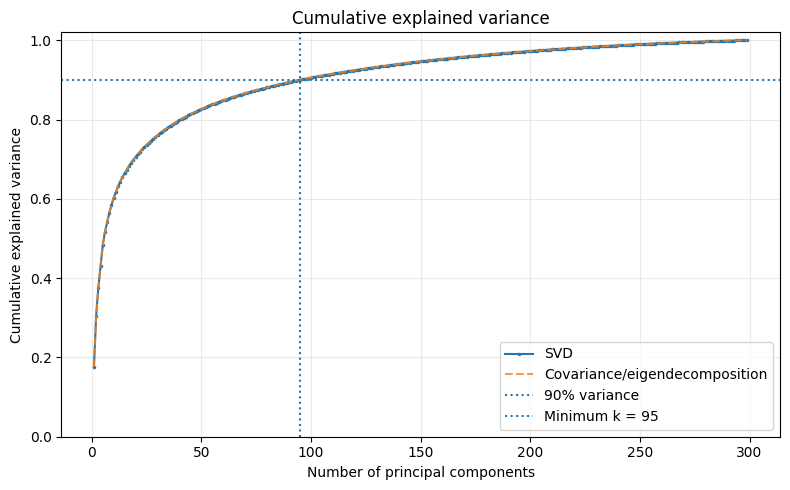

Minimum components needed for at least 90% variance: 95
Achieved cumulative variance: 90.0028%


In [8]:
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cumulative_svd) + 1), cumulative_svd,
         marker=".", markersize=3, label="SVD")
plt.plot(np.arange(1, len(cumulative_cov) + 1), cumulative_cov,
         linestyle="--", alpha=0.8, label="Covariance/eigendecomposition")
plt.axhline(0.90, linestyle=":", label="90% variance")
k90 = int(np.searchsorted(cumulative_svd, 0.90) + 1)
plt.axvline(k90, linestyle=":", label=f"Minimum k = {k90}")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance")
plt.ylim(0, 1.02)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "cumulative_explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Minimum components needed for at least 90% variance: {k90}")
print(f"Achieved cumulative variance: {cumulative_svd[k90 - 1]:.4%}")
assert cumulative_svd[k90 - 1] >= 0.90

## 7. Visualize the mean face and eigenfaces

Eigenfaces are principal directions reshaped into the original image dimensions. They often look like ghostly light/dark face patterns rather than ordinary photographs.

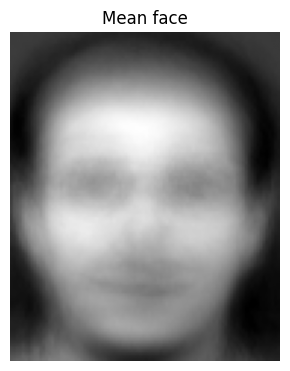

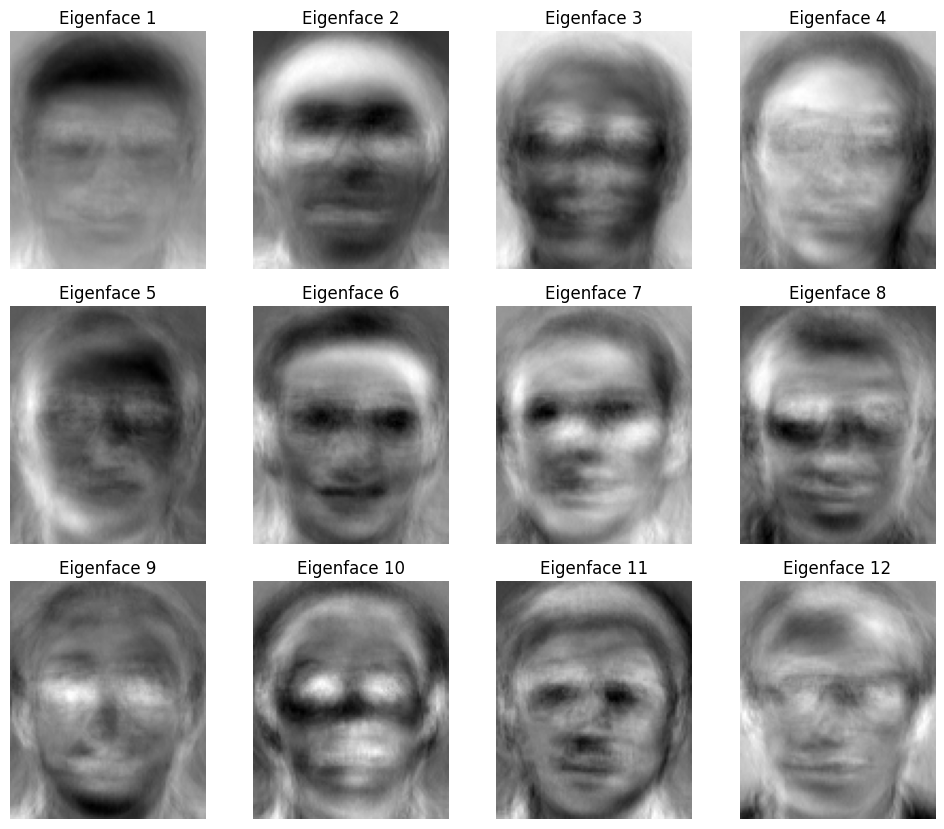

In [9]:
fig, ax = plt.subplots(figsize=(3, 4))
ax.imshow(mean_face.reshape(image_height, image_width), cmap="gray")
ax.set_title("Mean face")
ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "mean_face.png", dpi=150, bbox_inches="tight")
plt.show()

n_show = min(12, len(components_svd))
n_cols = 4
n_rows = int(np.ceil(n_show / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 2.8 * n_rows))
axes = np.asarray(axes).reshape(-1)
for i in range(len(axes)):
    axes[i].axis("off")
    if i < n_show:
        # Eigenvectors have arbitrary sign. Display each one with its own contrast range.
        eigenface = components_svd[i].reshape(image_height, image_width)
        axes[i].imshow(eigenface, cmap="gray")
        axes[i].set_title(f"Eigenface {i + 1}")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "eigenfaces.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Project faces into PCA space and reconstruct them

The retained SVD directions are used as the main PCA basis. Test images are centered using the **training mean face**, then projected. Reconstruction maps coefficients back to pixel space and adds the mean face.

The 90%-variance model is the assignment's primary compact representation. Additional component counts are evaluated later for recognition.

In [10]:
components_90 = components_svd[:k90]

def pca_transform(X_input, mean, components):
    return (X_input - mean) @ components.T

def pca_inverse_transform(scores, mean, components):
    return scores @ components + mean

Z_train_90 = pca_transform(X_train, mean_face, components_90)
Z_test_90 = pca_transform(X_test, mean_face, components_90)
X_test_reconstructed_90 = pca_inverse_transform(Z_test_90, mean_face, components_90)

mse_per_image = np.mean((X_test - X_test_reconstructed_90) ** 2, axis=1)
rmse_per_image = np.sqrt(mse_per_image)
print("Training PCA feature shape:", Z_train_90.shape)
print("Test PCA feature shape:", Z_test_90.shape)
print(f"Mean reconstruction MSE: {mse_per_image.mean():.3f}")
print(f"Mean reconstruction RMSE: {rmse_per_image.mean():.3f} intensity levels")

Training PCA feature shape: (300, 95)
Test PCA feature shape: (100, 95)
Mean reconstruction MSE: 333.635
Mean reconstruction RMSE: 18.041 intensity levels


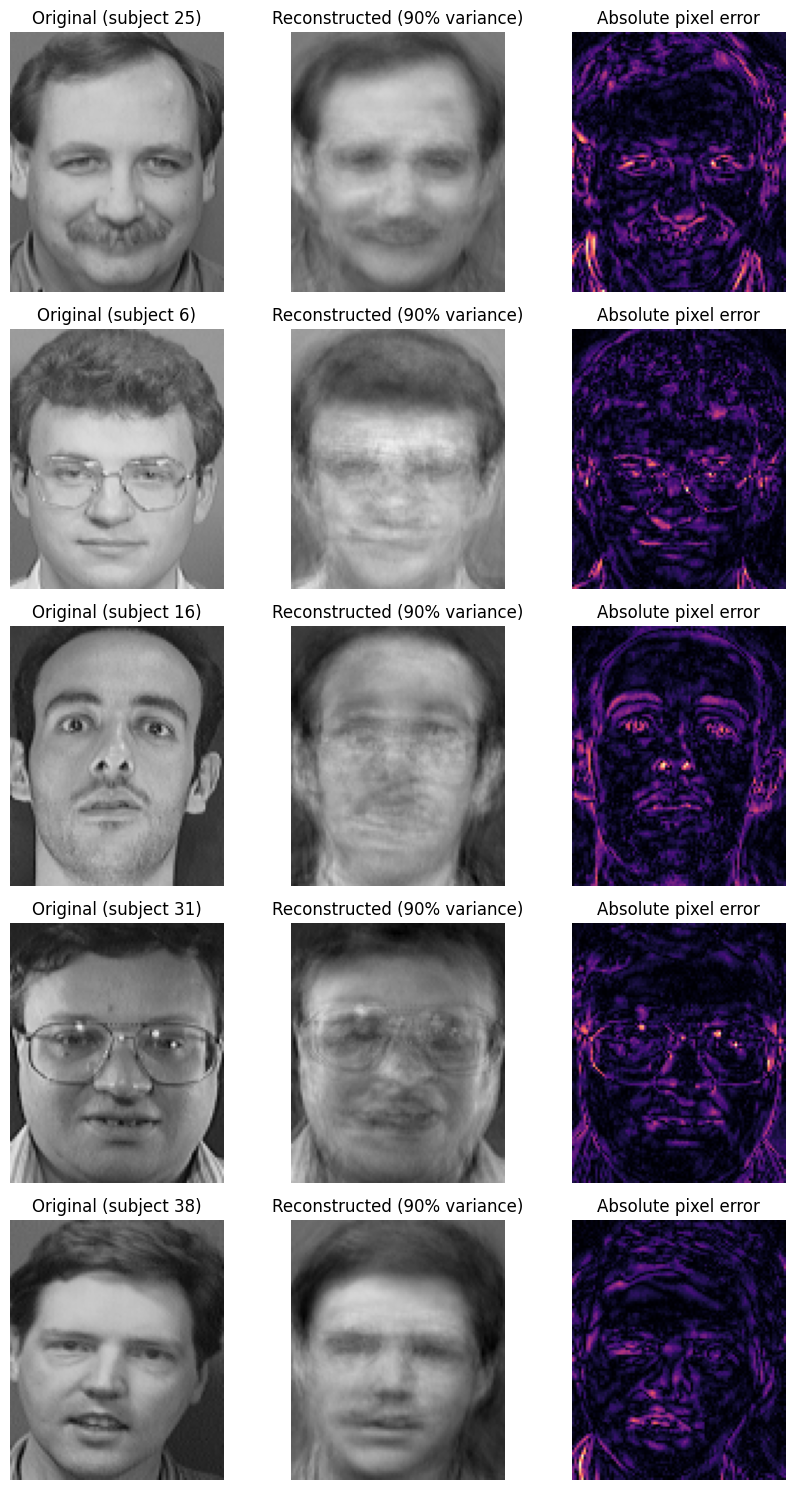

In [11]:
n_examples = min(5, len(X_test))
fig, axes = plt.subplots(n_examples, 3, figsize=(9, 3 * n_examples))
if n_examples == 1:
    axes = axes.reshape(1, -1)

for i in range(n_examples):
    original = X_test[i].reshape(image_height, image_width)
    reconstructed = X_test_reconstructed_90[i].reshape(image_height, image_width)
    error = np.abs(original.astype(float) - reconstructed)
    axes[i, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(f"Original (subject {y_test[i]})")
    axes[i, 1].imshow(np.clip(reconstructed, 0, 255), cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("Reconstructed (90% variance)")
    axes[i, 2].imshow(error, cmap="magma")
    axes[i, 2].set_title("Absolute pixel error")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "reconstruction_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Compare storage requirements

For a fair simple comparison, count one scalar per original pixel versus the retained PCA coefficients plus one shared mean face and the PCA basis. This is a count of scalar values, not a byte-exact file-size comparison; metadata, data types, compression, and serialization overhead are not included.

In [12]:
original_scalars_per_image = n_pixels
pca_scalars_per_image = k90
original_dataset_scalars = n_images * n_pixels
pca_dataset_scalars_including_shared_model = (
    n_images * k90 + n_pixels + k90 * n_pixels
)
compression_ratio_per_image_coefficients_only = n_pixels / k90
dataset_scalar_reduction_percent = 100 * (
    1 - pca_dataset_scalars_including_shared_model / original_dataset_scalars
)

storage_table = pd.DataFrame([
    {"Representation": "Original pixel vector", "Scalars per image": original_scalars_per_image,
     "Shared model scalars": 0},
    {"Representation": f"PCA coefficients ({k90} components)",
     "Scalars per image": pca_scalars_per_image,
     "Shared model scalars": n_pixels + k90 * n_pixels}
])
display(storage_table)
print(f"Per-image coefficient reduction factor (ignoring shared model): "
      f"{compression_ratio_per_image_coefficients_only:.2f}×")
print(f"Dataset scalar-count reduction including shared mean and basis: "
      f"{dataset_scalar_reduction_percent:.2f}%")

,Representation,Scalars per image,Shared model scalars
0,Original pixel vector,10304,0
1,PCA coefficients (95 components),95,989184


Per-image coefficient reduction factor (ignoring shared model): 108.46×
Dataset scalar-count reduction including shared mean and basis: 75.08%


## 10. Face matching by nearest training image

For each test image, choose the training image with the smallest Euclidean distance. Run this baseline on raw pixel vectors and on the 90%-variance PCA coefficients. The predicted subject is the label of the nearest training image.

To keep distance calculations manageable, distances are computed in test batches using squared Euclidean distance. Squared distance gives the same nearest neighbour as Euclidean distance, and avoids unnecessary square roots.

In [13]:
def nearest_neighbor_predict(X_train_features, y_train_labels, X_query, batch_size=32):
    predictions = []
    for start in range(0, len(X_query), batch_size):
        batch = X_query[start:start + batch_size]
        # ||a-b||^2 = ||a||^2 + ||b||^2 - 2 a.b
        train_sq = np.sum(X_train_features ** 2, axis=1)[None, :]
        query_sq = np.sum(batch ** 2, axis=1)[:, None]
        distances_sq = query_sq + train_sq - 2 * (batch @ X_train_features.T)
        distances_sq = np.maximum(distances_sq, 0.0)
        nearest_indices = np.argmin(distances_sq, axis=1)
        predictions.extend(y_train_labels[nearest_indices])
    return np.asarray(predictions)

pred_raw_nn = nearest_neighbor_predict(X_train, y_train, X_test)
pred_pca_nn = nearest_neighbor_predict(Z_train_90, y_train, Z_test_90)

acc_raw_nn = accuracy_score(y_test, pred_raw_nn)
acc_pca_nn = accuracy_score(y_test, pred_pca_nn)

nn_results = pd.DataFrame([
    {"Method": "Nearest neighbour — raw pixels", "Accuracy": acc_raw_nn},
    {"Method": f"Nearest neighbour — PCA ({k90} components)", "Accuracy": acc_pca_nn},
])
display(nn_results.style.format({"Accuracy": "{:.2%}"}))

,Method,Accuracy
0,Nearest neighbour — raw pixels,96.00%
1,Nearest neighbour — PCA (95 components),97.00%


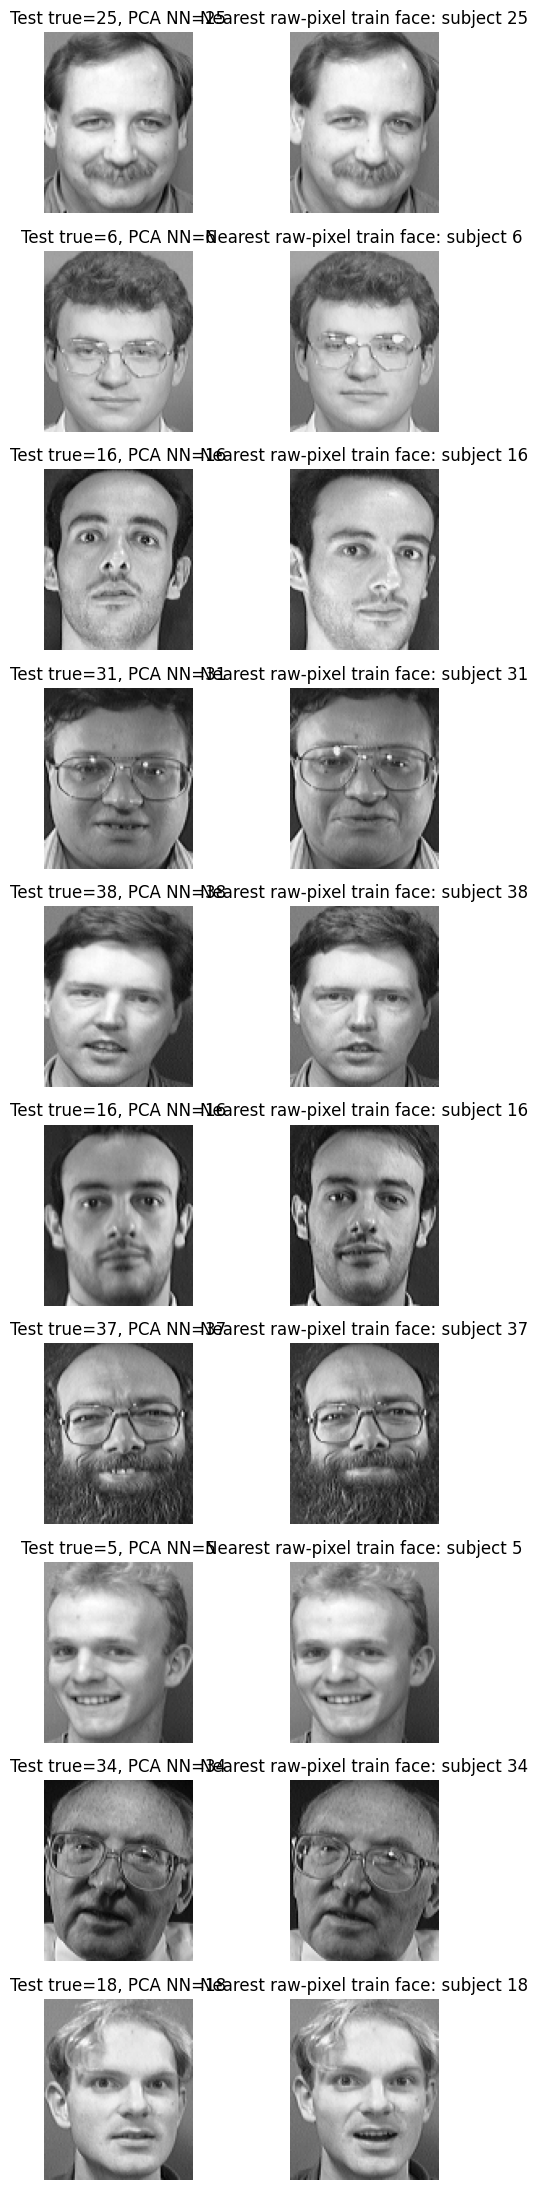

,Test image,True subject,Raw-pixel NN prediction,PCA NN prediction,Raw NN correct,PCA NN correct
0,3.pgm,25,25,25,True,True
1,4.pgm,6,6,6,True,True
2,9.pgm,16,16,16,True,True
3,2.pgm,31,31,31,True,True
4,3.pgm,38,38,38,True,True
5,6.pgm,16,16,16,True,True
6,2.pgm,37,37,37,True,True
7,7.pgm,5,5,5,True,True
8,5.pgm,34,34,34,True,True
9,2.pgm,18,18,18,True,True


In [14]:
# Inspect several matches, including whether each match was correct.
n_inspect = min(10, len(X_test))
fig, axes = plt.subplots(n_inspect, 2, figsize=(6, 2.2 * n_inspect))
if n_inspect == 1:
    axes = axes.reshape(1, -1)

for i in range(n_inspect):
    nearest_raw_idx = np.argmin(np.sum((X_train - X_test[i]) ** 2, axis=1))
    axes[i, 0].imshow(X_test[i].reshape(image_height, image_width), cmap="gray")
    axes[i, 0].set_title(f"Test true={y_test[i]}, PCA NN={pred_pca_nn[i]}")
    axes[i, 1].imshow(X_train[nearest_raw_idx].reshape(image_height, image_width), cmap="gray")
    axes[i, 1].set_title(f"Nearest raw-pixel train face: subject {y_train[nearest_raw_idx]}")
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "nearest_match_examples.png", dpi=150, bbox_inches="tight")
plt.show()

match_inspection = pd.DataFrame({
    "Test image": [Path(p).name for p in paths_test[:n_inspect]],
    "True subject": y_test[:n_inspect],
    "Raw-pixel NN prediction": pred_raw_nn[:n_inspect],
    "PCA NN prediction": pred_pca_nn[:n_inspect],
    "Raw NN correct": pred_raw_nn[:n_inspect] == y_test[:n_inspect],
    "PCA NN correct": pred_pca_nn[:n_inspect] == y_test[:n_inspect],
})
display(match_inspection)

## 11. Traditional machine-learning classifiers on PCA features

Train at least two traditional classifiers using the PCA representation. This notebook compares KNN, Logistic Regression, and RBF SVM. These classifiers are used only for the final ML comparison; PCA itself remains implemented with NumPy.

The first comparison uses the PCA component count that preserves at least 90% variance. Then the notebook evaluates multiple component counts to show the trade-off between compactness and recognition accuracy. Hyperparameter settings are stated explicitly for reproducibility.

In [15]:
# Models are defined explicitly below.
classifiers_90 = {
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3, metric="euclidean"),
    "Logistic Regression": LogisticRegression(
        max_iter=3000, solver="lbfgs", random_state=RANDOM_STATE
    ),
    "SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale"),
}

classifier_predictions_90 = {}
classifier_rows_90 = []
for name, model in classifiers_90.items():
    model.fit(Z_train_90, y_train)
    pred = model.predict(Z_test_90)
    classifier_predictions_90[name] = pred
    classifier_rows_90.append({
        "Method": f"{name} — PCA ({k90} components)",
        "Accuracy": accuracy_score(y_test, pred)
    })

comparison_90 = pd.concat([
    nn_results,
    pd.DataFrame(classifier_rows_90)
], ignore_index=True)
display(comparison_90.style.format({"Accuracy": "{:.2%}"}))
comparison_90.to_csv(RESULTS_DIR / "recognition_comparison_90_variance.csv", index=False)

,Method,Accuracy
0,Nearest neighbour — raw pixels,96.00%
1,Nearest neighbour — PCA (95 components),97.00%
2,KNN (k=3) — PCA (95 components),97.00%
3,Logistic Regression — PCA (95 components),98.00%
4,SVM (RBF) — PCA (95 components),98.00%


## 12. Experiment with component counts

For each selected component count, train each classifier on the corresponding PCA coefficients and report test accuracy. Counts are capped at the number of available principal directions. This experiment uses the same fixed train/test split for all settings.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Components,Cumulative variance,Method,Accuracy
1,5,48.27%,KNN (k=3),84.00%
5,10,60.30%,KNN (k=3),93.00%
9,20,70.59%,KNN (k=3),94.00%
13,40,79.84%,KNN (k=3),96.00%
17,60,84.85%,KNN (k=3),96.00%
21,95,90.00%,KNN (k=3),97.00%
2,5,48.27%,Logistic Regression,78.00%
6,10,60.30%,Logistic Regression,91.00%
10,20,70.59%,Logistic Regression,98.00%
14,40,79.84%,Logistic Regression,99.00%


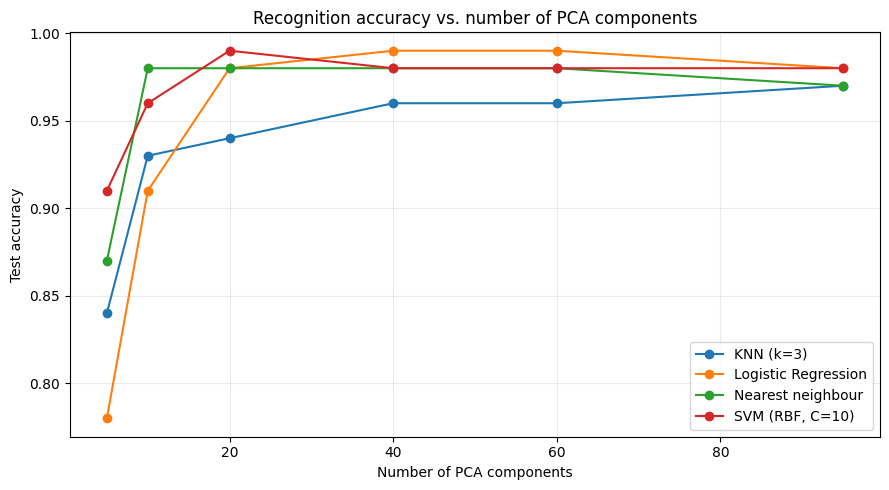

In [16]:
candidate_ks = sorted(set([
    min(5, len(components_svd)),
    min(10, len(components_svd)),
    min(20, len(components_svd)),
    min(k90, len(components_svd)),
    min(40, len(components_svd)),
    min(60, len(components_svd)),
]))
candidate_ks = [k for k in candidate_ks if k >= 1]

tuning_rows = []
for k in candidate_ks:
    comps = components_svd[:k]
    Ztr = pca_transform(X_train, mean_face, comps)
    Zte = pca_transform(X_test, mean_face, comps)
    for name, model in {
        "Nearest neighbour": None,
        "KNN (k=3)": KNeighborsClassifier(n_neighbors=3, metric="euclidean"),
        "Logistic Regression": LogisticRegression(
            max_iter=3000, solver="lbfgs", random_state=RANDOM_STATE
        ),
        "SVM (RBF, C=10)": SVC(kernel="rbf", C=10, gamma="scale"),
    }.items():
        if model is None:
            pred = nearest_neighbor_predict(Ztr, y_train, Zte)
        else:
            model.fit(Ztr, y_train)
            pred = model.predict(Zte)
        tuning_rows.append({
            "Components": k,
            "Cumulative variance": cumulative_svd[k - 1],
            "Method": name,
            "Accuracy": accuracy_score(y_test, pred)
        })

tuning_results = pd.DataFrame(tuning_rows)
display(tuning_results.sort_values(["Method", "Components"]).style.format({
    "Cumulative variance": "{:.2%}", "Accuracy": "{:.2%}"
}))
tuning_results.to_csv(RESULTS_DIR / "component_count_experiment.csv", index=False)

plt.figure(figsize=(9, 5))
for method, group in tuning_results.groupby("Method"):
    group = group.sort_values("Components")
    plt.plot(group["Components"], group["Accuracy"], marker="o", label=method)
plt.xlabel("Number of PCA components")
plt.ylabel("Test accuracy")
plt.title("Recognition accuracy vs. number of PCA components")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "accuracy_vs_components.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. Inspect incorrect matches and a confusion matrix

This cell reports examples where PCA nearest-neighbour matching predicted the wrong subject and visualizes the confusion matrix for the best-performing classifier in the 90%-variance comparison. The chosen model is based on this held-out test set, so treat it as a descriptive comparison rather than an unbiased final model-selection estimate.

PCA nearest-neighbour errors: 3 / 100


,Test image,True subject,Predicted subject
0,1.pgm,35,40
1,5.pgm,40,5
2,9.pgm,10,23


Best method in the 90%-variance comparison: Logistic Regression — PCA (95 components)


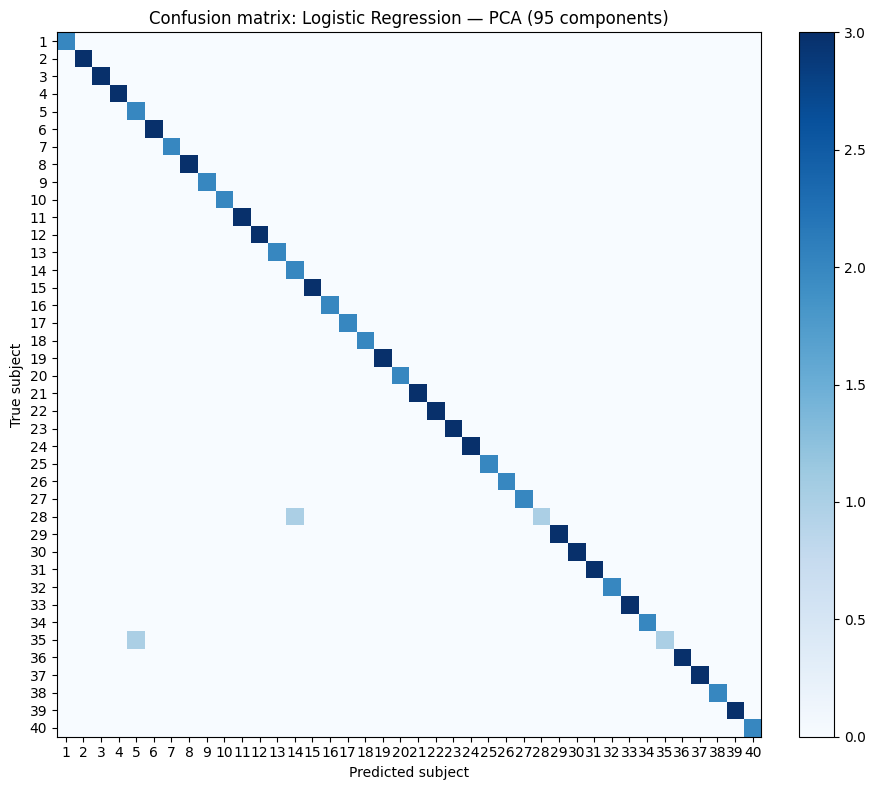

In [17]:
wrong = np.flatnonzero(pred_pca_nn != y_test)
print(f"PCA nearest-neighbour errors: {len(wrong)} / {len(y_test)}")
if len(wrong):
    display(pd.DataFrame({
        "Test image": [Path(paths_test[i]).name for i in wrong],
        "True subject": y_test[wrong],
        "Predicted subject": pred_pca_nn[wrong],
    }).head(15))
else:
    print("No PCA nearest-neighbour errors on this test split.")

best_row = comparison_90.loc[comparison_90["Accuracy"].idxmax()]
best_method_label = best_row["Method"]
print("Best method in the 90%-variance comparison:", best_method_label)

if best_method_label.startswith("Nearest neighbour — raw"):
    best_predictions = pred_raw_nn
elif best_method_label.startswith("Nearest neighbour — PCA"):
    best_predictions = pred_pca_nn
else:
    classifier_name = best_method_label.split(" — PCA")[0]
    best_predictions = classifier_predictions_90[classifier_name]

labels = np.sort(np.unique(y))
cm = confusion_matrix(y_test, best_predictions, labels=labels)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
ax.set_title(f"Confusion matrix: {best_method_label}")
ax.set_xlabel("Predicted subject")
ax.set_ylabel("True subject")
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "confusion_matrix_best_90_variance.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Verification tests

These checks verify data dimensions, label coverage, the 90% variance target, finite PCA projections/reconstructions, and agreement between covariance/eigendecomposition and SVD eigenvalues. Small floating-point differences are expected.

In [18]:
# Test 1: image matrix and labels are aligned.
assert X.shape[0] == y.shape[0] == len(image_paths)
assert X.shape[1] == image_height * image_width

# Test 2: all subjects occur in both train and test sets.
assert set(np.unique(y_train)) == set(np.unique(y_test)) == set(np.unique(y))

# Test 3: PCA selected enough components to preserve >=90% variance.
assert cumulative_svd[k90 - 1] >= 0.90
assert k90 == int(np.searchsorted(cumulative_svd, 0.90) + 1)

# Test 4: projection and reconstruction have expected shapes and finite values.
assert Z_train_90.shape == (len(X_train), k90)
assert Z_test_90.shape == (len(X_test), k90)
assert X_test_reconstructed_90.shape == X_test.shape
assert np.isfinite(Z_train_90).all()
assert np.isfinite(X_test_reconstructed_90).all()

# Test 5: covariance-based and SVD variances agree for leading components.
n_check = min(10, len(explained_variance_cov), len(explained_variance_svd))
np.testing.assert_allclose(
    explained_variance_cov[:n_check],
    explained_variance_svd[:n_check],
    rtol=1e-5, atol=1e-7
)

# Test 6: all recognition outputs have one prediction per test image.
assert len(pred_raw_nn) == len(pred_pca_nn) == len(y_test)
assert all(len(pred) == len(y_test) for pred in classifier_predictions_90.values())

print("All verification tests passed.")

All verification tests passed.


In [19]:
summary = {
    "images": int(n_images),
    "subjects": int(n_subjects),
    "image_height": int(image_height),
    "image_width": int(image_width),
    "train_images": int(len(X_train)),
    "test_images": int(len(X_test)),
    "components_for_90_percent_variance": int(k90),
    "variance_preserved": float(cumulative_svd[k90 - 1]),
    "mean_reconstruction_mse": float(mse_per_image.mean()),
    "raw_pixel_nearest_neighbor_accuracy": float(acc_raw_nn),
    "pca_nearest_neighbor_accuracy": float(acc_pca_nn),
    "best_90_variance_method": str(best_method_label),
    "best_90_variance_accuracy": float(best_row["Accuracy"]),
}
summary_df = pd.DataFrame([summary])
display(summary_df)
summary_df.to_csv(RESULTS_DIR / "summary.csv", index=False)

print("\nSuggested README observations (based on this run):")
print(f"- The dataset contains {n_images} images from {n_subjects} subjects.")
print(f"- {k90} principal components preserve {cumulative_svd[k90 - 1]:.2%} of training-set variance.")
print(f"- Raw-pixel nearest-neighbour accuracy: {acc_raw_nn:.2%}.")
print(f"- PCA nearest-neighbour accuracy: {acc_pca_nn:.2%}.")
print(f"- Best method in the 90%-variance comparison: {best_method_label} "
      f"({best_row['Accuracy']:.2%}).")
print(f"- Mean reconstruction RMSE: {rmse_per_image.mean():.2f} intensity levels.")
print("\nGenerated folders:", FIGURE_DIR.resolve(), "and", RESULTS_DIR.resolve())

,images,subjects,image_height,image_width,train_images,test_images,components_for_90_percent_variance,variance_preserved,mean_reconstruction_mse,raw_pixel_nearest_neighbor_accuracy,pca_nearest_neighbor_accuracy,best_90_variance_method,best_90_variance_accuracy
0,400,40,112,92,300,100,95,0.900028,333.635446,0.96,0.97,Logistic Regression — PCA (95 components),0.98



Suggested README observations (based on this run):
- The dataset contains 400 images from 40 subjects.
- 95 principal components preserve 90.00% of training-set variance.
- Raw-pixel nearest-neighbour accuracy: 96.00%.
- PCA nearest-neighbour accuracy: 97.00%.
- Best method in the 90%-variance comparison: Logistic Regression — PCA (95 components) (98.00%).
- Mean reconstruction RMSE: 18.04 intensity levels.

Generated folders: /content/figures and /content/results
